# Who moves the Nikkei? Drivers of Japanese equity returns, 2005 to 2026
*Statistics & Econometrics, group project, Audencia*

**Research question.** To what extent do external macro-financial factors (the yen, US equities, oil,
the US-Japan rate gap) explain the monthly return of the Nikkei 225, do they still matter once Japan's
own Fama-French factors are controlled for, and did the 2026 oil shock change the answer?

**Three parts**
1. *External drivers:* `R_NKY = b0 + b1 R_USDJPY + b2 R_SP500 + b3 R_OIL + b4 dRATEGAP + e`
2. *The 2026 oil regime:* a dummy from March 2026, its interaction with oil, abnormal returns and a
   predictive Chow test.
3. *Japan's own factors:* Nikkei excess return (USD) on the Fama-French **Japan** 5 factors, then adding
   the external drivers (nested models M0 to M4).

**Data.** Nikkei, USD/JPY and the two 10-year yields from Stooq; Brent (DCOILBRENTEU) from FRED; S&P 500
from Yahoo Finance (^GSPC); Japan factors from the Kenneth French Data Library. Everything is rebuilt on a
single convention (month-end levels) rather than spliced, so the 2026 break is in the data, not in the sources.
`dataset.csv` runs to September 2026; `dataset_ff_japan.csv` stops in August 2026, where French's Japan factors end.

## 1. Settings

In [1]:
import numpy as np, pandas as pd, statsmodels.api as sm
import warnings; warnings.filterwarnings("ignore")

START, END = "2005-12-31", "2026-09-30"
BREAK = pd.Timestamp("2026-03-31")      # premier mois du regime petrolier 2026
Y  = "R_NKY"
XS = ["R_USDJPY", "R_SP500", "R_OIL", "dRATEDIFF"]
EXPECTED_SIGN = {"R_USDJPY": "+", "R_SP500": "+", "R_OIL": "-", "dRATEDIFF": "+/-"}

## 2. Data: external drivers, and their statistical properties

Session 6 asks us to *describe the data before modelling it*. Beyond the first two moments we report
skewness, kurtosis, the Jarque-Bera normality test and the ADF unit-root test, because the validity of
the inference in section 3 depends on what these say.

In [2]:
from scipy import stats
from statsmodels.tsa.stattools import adfuller

data = pd.read_csv("dataset.csv", index_col=0, parse_dates=True)
print(f"{len(data)} monthly observations, {data.index[0]:%Y-%m} to {data.index[-1]:%Y-%m}")

rows = {}
for v in [Y] + XS:
    s = data[v].dropna()
    sc = 100 if v != "dRATEDIFF" else 1      # returns in %, the rate gap stays in points
    rows[v] = {"N": len(s), "Mean": s.mean()*sc, "Median": s.median()*sc, "Std": s.std()*sc,
               "Min": s.min()*sc, "Max": s.max()*sc,
               "Skew": stats.skew(s), "Kurt": stats.kurtosis(s, fisher=False),
               "JB p": stats.jarque_bera(s).pvalue, "ADF p": adfuller(s, autolag="AIC")[1]}
desc = pd.DataFrame(rows).T
print(desc.to_string(float_format=lambda x: f"{x:9.4f}"))
print("\nKurtosis is raw (3 = normal). Every return series is leptokurtic and JB rejects normality,")
print("which is the empirical motivation for the maximum-likelihood work in section 12.")
print("ADF rejects a unit root everywhere, so the series are stationary and OLS inference is standard.")
print("\nCorrelation of the regressors")
print(data[XS].corr().to_string(float_format=lambda x: f"{x:7.3f}"))

250 monthly observations, 2005-12 to 2026-09
                  N      Mean    Median       Std       Min       Max      Skew      Kurt      JB p     ADF p
R_NKY      250.0000    0.6006    1.0014    5.5984  -27.2162   15.3959   -0.6825    5.1232    0.0000    0.0000
R_USDJPY   250.0000    0.1091    0.0631    2.7364   -7.4572    8.6968    0.0893    3.6470    0.0957    0.0000
R_SP500    250.0000    0.7249    1.2912    4.3753  -18.5636   11.9421   -0.7671    4.6143    0.0000    0.0000
R_OIL      250.0000    0.3111    1.0571   13.9694 -123.9886   63.4298   -2.3326   29.4759    0.0000    0.0000
dRATEDIFF  250.0000   -0.0033   -0.0057    0.2171   -0.9360    0.6140   -0.1465    4.6912    0.0000    0.0000

Kurtosis is raw (3 = normal). Every return series is leptokurtic and JB rejects normality,
which is the empirical motivation for the maximum-likelihood work in section 12.
ADF rejects a unit root everywhere, so the series are stationary and OLS inference is standard.

Correlation of the regres

## 3. Model 1: external drivers, OLS

In [3]:
Xmat  = sm.add_constant(data[XS])
model = sm.OLS(data[Y], Xmat).fit()
print(model.summary())
print("\nNewey-West (HAC, 4 lags) robust standard errors:")
print(sm.OLS(data[Y], Xmat).fit(cov_type="HAC", cov_kwds={"maxlags": 4}).summary().tables[1])

                            OLS Regression Results                            
Dep. Variable:                  R_NKY   R-squared:                       0.640
Model:                            OLS   Adj. R-squared:                  0.634
Method:                 Least Squares   F-statistic:                     108.9
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           3.38e-53
Time:                        11:02:15   Log-Likelihood:                 494.19
No. Observations:                 250   AIC:                            -978.4
Df Residuals:                     245   BIC:                            -960.8
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0012      0.002     -0.545      0.5

## 4. Signs, multicollinearity and diagnostics

In [4]:
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_breusch_godfrey
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.tsa.stattools import adfuller

for x in XS:
    got = "+" if model.params[x] > 0 else "-"
    print(f"{x:<10} coef {model.params[x]:+.4f}  expected {EXPECTED_SIGN[x]:<3} got {got}  p = {model.pvalues[x]:.3f}")
print("\nCorrelation of regressors:\n", data[XS].corr().round(2))
print("\nVIF:", {c: round(vif(Xmat.values, i), 2) for i, c in enumerate(Xmat.columns) if c != "const"})
print(f"\nBreusch-Pagan p = {het_breuschpagan(model.resid, Xmat)[1]:.3f}")
print(f"Breusch-Godfrey (4 lags) p = {acorr_breusch_godfrey(model, nlags=4)[1]:.3f}")
print(f"Durbin-Watson = {durbin_watson(model.resid):.3f}")
print(f"Jarque-Bera p = {jarque_bera(model.resid)[1]:.3f}")
print("ADF p-values:", {c: round(adfuller(data[c])[1], 4) for c in [Y] + XS})

R_USDJPY   coef +0.8696  expected +   got +  p = 0.000
R_SP500    coef +0.8612  expected +   got +  p = 0.000
R_OIL      coef -0.0137  expected -   got -  p = 0.427
dRATEDIFF  coef -0.0127  expected +/- got -  p = 0.294

Correlation of regressors:
            R_USDJPY  R_SP500  R_OIL  dRATEDIFF
R_USDJPY       1.00     0.08   0.08       0.50
R_SP500        0.08     1.00   0.33       0.06
R_OIL          0.08     0.33   1.00       0.32
dRATEDIFF      0.50     0.06   0.32       1.00

VIF: {'R_USDJPY': np.float64(1.35), 'R_SP500': np.float64(1.13), 'R_OIL': np.float64(1.26), 'dRATEDIFF': np.float64(1.49)}

Breusch-Pagan p = 0.150
Breusch-Godfrey (4 lags) p = 0.319
Durbin-Watson = 2.120
Jarque-Bera p = 0.183
ADF p-values: {'R_NKY': 0.0, 'R_USDJPY': 0.0, 'R_SP500': 0.0, 'R_OIL': 0.0, 'dRATEDIFF': 0.0}


## 5. Further tests used in the slides

In [5]:
# t-tests of a value other than zero (general linear hypotheses)
for x in ["R_SP500", "R_USDJPY"]:
    t = (model.params[x] - 1) / model.bse[x]
    print(f"H0: beta({x}) = 1  ->  t = {t:.2f}, p = {float(model.t_test(f'{x} = 1').pvalue):.4f}")

# joint F-test: can we drop oil and the rate gap?
ft = model.f_test("R_OIL = 0, dRATEDIFF = 0")
restricted = sm.OLS(data[Y], sm.add_constant(data[["R_USDJPY", "R_SP500"]])).fit()
print(f"\nH0: oil = rate gap = 0  ->  F = {float(np.squeeze(ft.fvalue)):.2f}, p = {float(ft.pvalue):.3f}")
print(f"R2 full {model.rsquared:.3f} vs restricted {restricted.rsquared:.3f}")

# each driver on its own (simple regressions): the omitted-variable puzzle
print("\nSimple regressions, |t| alone vs in the full model:")
for x in XS:
    s = sm.OLS(data[Y], sm.add_constant(data[[x]])).fit()
    print(f"  {x:<10} alone t = {s.tvalues[x]:6.2f}  |  full model t = {model.tvalues[x]:6.2f}")

# economic size: effect of a 1-standard-deviation move, in Nikkei percentage points
print("\nEffect of a typical (1 sd) monthly move on the Nikkei, pp:")
for x in XS:
    print(f"  {x:<10} {model.params[x] * data[x].std() * 100:+.2f}")

H0: beta(R_SP500) = 1  ->  t = -2.66, p = 0.0084
H0: beta(R_USDJPY) = 1  ->  t = -1.43, p = 0.1533

H0: oil = rate gap = 0  ->  F = 1.28, p = 0.279
R2 full 0.640 vs restricted 0.636

Simple regressions, |t| alone vs in the full model:
  R_USDJPY   alone t =   7.93  |  full model t =   9.55
  R_SP500    alone t =  15.08  |  full model t =  16.49
  R_OIL      alone t =   3.36  |  full model t =  -0.80
  dRATEDIFF  alone t =   3.06  |  full model t =  -1.05

Effect of a typical (1 sd) monthly move on the Nikkei, pp:
  R_USDJPY   +2.38
  R_SP500    +3.77
  R_OIL      -0.19
  dRATEDIFF  -0.28


## 6. The 2026 oil shock

Brent moved more than +25% in three months of 2026: **March +57.5%**, July +31.9%, September +25.6%.
March is a +4.4 sigma move against the 2005-2025 distribution, so the regime is dated from March rather
than from September. A dummy on September alone would have been a single observation out of 250, and its
interaction with oil would have been perfectly collinear with the dummy itself.

In [6]:
print("Largest monthly oil moves in the sample:")
print((np.log(data["OIL"]).diff() * 100).nlargest(5).round(1).to_string())
sd_hist = (np.log(data["OIL"]).diff().loc[:"2025-12-31"]).std()
for m in ["2026-03-31", "2026-07-31", "2026-09-30"]:
    v = np.log(data["OIL"]).diff().loc[m]
    print(f"  {m[:7]}: {v*100:+6.2f}%   z vs 2005-2025 = {v/sd_hist:+.2f}")

Largest monthly oil moves in the sample:
Date
2020-05-31    63.4
2026-03-31    57.5
2026-07-31    31.9
2015-02-28    26.4
2009-05-31    25.6
  2026-03: +57.46%   z vs 2005-2025 = +4.35
  2026-07: +31.92%   z vs 2005-2025 = +2.42
  2026-09: +25.58%   z vs 2005-2025 = +1.94


In [7]:
d = data.copy()
d["D"] = (d.index >= BREAK).astype(float)
d["DxOIL"] = d["D"] * d["R_OIL"]

m_d = sm.OLS(d[Y], sm.add_constant(d[XS + ["D"]])).fit()
print(f"Dummy only:  D = {m_d.params['D']:+.4f}  t = {m_d.tvalues['D']:+.2f}  p = {m_d.pvalues['D']:.3f}")
print("-> the average month did not shift.\n")

m_i = sm.OLS(d[Y], sm.add_constant(d[XS + ["D", "DxOIL"]])).fit()
print(m_i.summary().tables[1])
oil_out, oil_in = m_i.params["R_OIL"], m_i.params["R_OIL"] + m_i.params["DxOIL"]
print(f"\nOil beta outside the regime: {oil_out:+.4f}")
print(f"Oil beta inside the regime:  {oil_in:+.4f}")
jt = m_i.f_test("D = 0, DxOIL = 0")
print(f"Joint F (D = DxOIL = 0): F = {float(np.squeeze(jt.fvalue)):.2f}, p = {float(jt.pvalue):.4g}")

Dummy only:  D = +0.0071  t = +0.55  p = 0.586
-> the average month did not shift.

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0010      0.002     -0.480      0.632      -0.005       0.003
R_USDJPY       0.8537      0.088      9.665      0.000       0.680       1.028
R_SP500        0.8070      0.052     15.454      0.000       0.704       0.910
R_OIL          0.0171      0.018      0.932      0.352      -0.019       0.053
dRATEDIFF     -0.0136      0.012     -1.164      0.245      -0.037       0.009
D              0.0188      0.013      1.456      0.147      -0.007       0.044
DxOIL         -0.1926      0.046     -4.205      0.000      -0.283      -0.102

Oil beta outside the regime: +0.0171
Oil beta inside the regime:  -0.1755
Joint F (D = DxOIL = 0): F = 9.00, p = 0.0001698


### Abnormal returns

The model is estimated on the pre-break months only, then used to forecast each month of the regime.
The standard error is the full forecast error, so it includes both parameter uncertainty and the
residual variance.

In [8]:
pre, post = data.loc[:BREAK - pd.Timedelta(days=1)], data.loc[BREAK:]
m_pre = sm.OLS(pre[Y], sm.add_constant(pre[XS])).fit()
pred  = m_pre.get_prediction(sm.add_constant(post[XS], has_constant="add"))
ar    = post[Y] - pred.predicted_mean
se_f  = pd.Series(np.sqrt(pred.var_pred_mean + m_pre.mse_resid), index=post.index)

tab = pd.DataFrame({"actual_%": post[Y] * 100, "fitted_%": pred.predicted_mean * 100,
                    "abnormal_%": ar * 100, "t": ar / se_f})
tab["cumulative_%"] = tab["abnormal_%"].cumsum()
print(f"Estimated on {int(m_pre.nobs)} pre-break months, forecasting {len(post)}:")
print(tab.round(2).to_string())
print(f"\nCAR = {tab['abnormal_%'].sum():+.2f}%   t = {ar.sum()/np.sqrt((se_f**2).sum()):+.2f}")
print("-> March is the one month the model badly misses; cumulatively the shock washes out.")

Estimated on 243 pre-break months, forecasting 7:
            actual_%  fitted_%  abnormal_%     t  cumulative_%
Date                                                          
2026-03-31    -14.19     -1.85      -12.34 -3.56        -12.34
2026-04-30     14.93      6.69        8.24  2.50         -4.11
2026-05-31     11.23      4.89        6.34  1.91          2.24
2026-06-30      5.48      0.31        5.17  1.57          7.41
2026-07-31     -8.49     -1.66       -6.83 -2.06          0.58
2026-08-31      2.98      2.31        0.67  0.21          1.25
2026-09-30      0.66     -1.99        2.66  0.80          3.91

CAR = +3.91%   t = +0.44
-> March is the one month the model badly misses; cumulatively the shock washes out.


### Predictive Chow (forecast failure test)

In [9]:
from scipy import stats
h, k, n1 = len(post), len(XS) + 1, int(m_pre.nobs)
ssr_full = sm.OLS(data[Y], sm.add_constant(data[XS])).fit().ssr
F_pred = ((ssr_full - m_pre.ssr) / h) / (m_pre.ssr / (n1 - k))
print(f"Predictive Chow: F({h}, {n1-k}) = {F_pred:.3f}, p = {1 - stats.f.cdf(F_pred, h, n1-k):.4g}")

s2 = sm.OLS(post[Y], sm.add_constant(post[XS])).fit()
ssr_u = m_pre.ssr + s2.ssr
F_c = ((ssr_full - ssr_u) / k) / (ssr_u / (len(data) - 2 * k))
print(f"Classic Chow:    F({k}, {len(data)-2*k}) = {F_c:.3f}, p = {1 - stats.f.cdf(F_c, k, len(data)-2*k):.4g}")
print("\nBoth reject stability. The break is the finding, not a defect of the model.")

Predictive Chow: F(7, 238) = 3.899, p = 0.0004826
Classic Chow:    F(5, 240) = 5.188, p = 0.0001535

Both reject stability. The break is the finding, not a defect of the model.


## 7. Figures

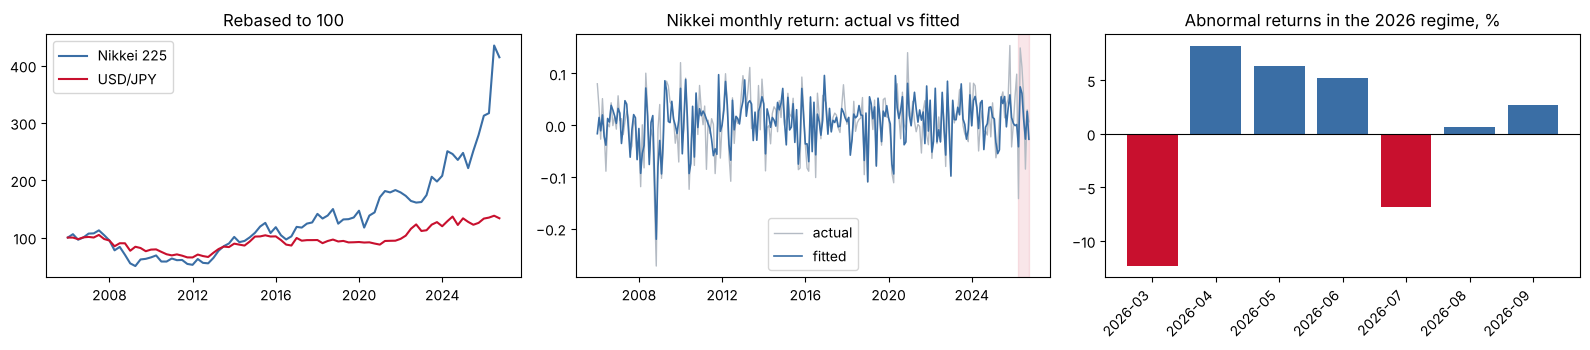

In [10]:
import matplotlib.pyplot as plt
NAVY, RED, GREY = "#3A6EA5", "#C8102E", "#B4BBC4"
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))

q = data[["NKY", "USDJPY"]].resample("QE").last(); q = q / q.iloc[0] * 100
ax[0].plot(q.index, q["NKY"], color=NAVY, label="Nikkei 225")
ax[0].plot(q.index, q["USDJPY"], color=RED, label="USD/JPY")
ax[0].set_title("Rebased to 100"); ax[0].legend()

ax[1].plot(data.index, data[Y], color=GREY, lw=1, label="actual")
ax[1].plot(data.index, model.fittedvalues, color=NAVY, lw=1.2, label="fitted")
ax[1].axvspan(BREAK, data.index[-1], color=RED, alpha=.10)
ax[1].set_title("Nikkei monthly return: actual vs fitted"); ax[1].legend()

# axe categoriel : des barres centrees sur les fins de mois tombent sur le tick du mois suivant
lab = [t.strftime("%Y-%m") for t in tab.index]
ax[2].bar(range(len(tab)), tab["abnormal_%"],
          color=[RED if v < 0 else NAVY for v in tab["abnormal_%"]])
ax[2].set_xticks(range(len(tab))); ax[2].set_xticklabels(lab, rotation=45, ha="right")
ax[2].axhline(0, color="black", lw=.8)
ax[2].set_title("Abnormal returns in the 2026 regime, %")
plt.tight_layout(); plt.show()

## 8. Model 2: Fama-French **Japan** factors

French's Japan factors are monthly, in % and **in US dollars**, with the US one-month T-bill as risk-free
rate. The Nikkei is therefore converted to dollars (`NKY / USDJPY`) before taking its excess return, so both
sides are in the same currency. These factors end in August 2026, so Model 2 stops one month before Model 1.

In [11]:
J = pd.read_csv("dataset_ff_japan.csv", index_col=0, parse_dates=True)
print(f"{len(J)} monthly observations, {J.index[0]:%Y-%m} to {J.index[-1]:%Y-%m}")
J.describe().T[["mean", "std", "min", "max"]].round(2)

248 monthly observations, 2006-01 to 2026-08


,mean,std,min,max
NKY_EX,0.43,4.96,-18.12,17.40
Mkt-RF,0.38,4.15,-13.55,10.92
SMB,0.02,2.18,-7.19,5.67
HML,0.40,3.07,-7.39,14.58
RMW,-0.08,1.79,-6.69,5.23
CMA,0.23,1.92,-6.12,7.54
R_USDJPY,0.12,2.74,-7.46,8.70
R_SP500,0.73,4.39,-18.56,11.94
RF,0.14,0.16,0.00,0.48
WML,0.01,3.61,-18.28,14.30


In [12]:
specs = {
    "M0 External only":       ["R_USDJPY", "R_SP500"],
    "M1 CAPM Japan":          ["Mkt-RF"],
    "M2 FF3 Japan":           ["Mkt-RF", "SMB", "HML"],
    "M3 FF5 Japan":           ["Mkt-RF", "SMB", "HML", "RMW", "CMA"],
    "M4 FF5 Japan + external":["Mkt-RF", "SMB", "HML", "RMW", "CMA", "R_USDJPY", "R_SP500"],
}
fits = {k: sm.OLS(J["NKY_EX"], sm.add_constant(J[v])).fit() for k, v in specs.items()}
star = lambda p: "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""
tb = pd.DataFrame({k: {v: f"{m.params[v]:.3f}{star(m.pvalues[v])}" for v in m.params.index} for k, m in fits.items()})
tb = tb.reindex(["const", "Mkt-RF", "SMB", "HML", "RMW", "CMA", "R_USDJPY", "R_SP500"]).fillna("")
tb.loc["R2"] = [f"{m.rsquared:.3f}" for m in fits.values()]
tb.loc["Adj. R2"] = [f"{m.rsquared_adj:.3f}" for m in fits.values()]
print("Coefficients (*** 1%, ** 5%, * 10%)"); print(tb.to_string())

m1, m3, m4 = (fits[k] for k in ["M1 CAPM Japan", "M3 FF5 Japan", "M4 FF5 Japan + external"])
for lab, (u, r) in {"Style factors (M3 vs M1)": (m3, m1),
                    "External drivers beyond Japan's factors (M4 vs M3)": (m4, m3)}.items():
    F, p, q_ = u.compare_f_test(r); print(f"\n{lab}: F = {F:.2f}, p = {p:.2g}, restrictions = {int(q_)}")
print(f"\nH0: Japan market beta = 1 in M3 -> t = {(m3.params['Mkt-RF'] - 1) / m3.bse['Mkt-RF']:.2f}")
print("Correlation HML vs RMW:", round(J["HML"].corr(J["RMW"]), 2))

X4 = sm.add_constant(J[specs["M4 FF5 Japan + external"]])
print("\nM4 with Newey-West standard errors:")
print(sm.OLS(J["NKY_EX"], X4).fit(cov_type="HAC", cov_kwds={"maxlags": 4}).summary().tables[1])
print(f"M4 diagnostics: BP p = {het_breuschpagan(m4.resid, X4)[1]:.4g}, "
      f"BG p = {acorr_breusch_godfrey(m4, nlags=4)[1]:.4g}, DW = {durbin_watson(m4.resid):.2f}, "
      f"JB p = {jarque_bera(m4.resid)[1]:.2g}, max VIF = {max(vif(X4.values, i) for i in range(1, X4.shape[1])):.2f}")
print("\nWith 2026 in the sample M4 fails homoskedasticity, autocorrelation and normality:")
print("its coefficients are read on the Newey-West standard errors above, under which the conclusions hold.")

Coefficients (*** 1%, ** 5%, * 10%)
         M0 External only M1 CAPM Japan M2 FF3 Japan M3 FF5 Japan M4 FF5 Japan + external
const              -0.156         0.009        0.112        0.086                   0.013
Mkt-RF                         1.108***     1.066***     1.079***                1.021***
SMB                                        -0.433***    -0.428***               -0.373***
HML                                        -0.201***    -0.158***               -0.168***
RMW                                                       0.164**                  0.150*
CMA                                                         0.075                  0.132*
R_USDJPY         -0.177**                                                         0.079**
R_SP500          0.834***                                                        0.101***
R2                  0.545         0.862        0.904        0.905                   0.912
Adj. R2             0.541         0.861        0.902        0.90

## 9. Session 7: from Fama-French to Carhart, does momentum add anything?

Session 7 presents the beta-pricing family: CAPM, FF3, FF5, **Carhart** (the momentum factor WML), and the
warning that comes with it. Harvey, Liu and Zhu count 316 published factors, so a factor is kept only if the
data demand it. We therefore estimate two further models and let nested F-tests arbitrate.

| | specification |
|---|---|
| **M5** | FF5 + WML (Carhart-style, six factors) |
| **M6** | FF5 without CMA, plus WML (five factors) |

`ALPHA = 0.10` throughout this part: the investment report in section 11 is written at the 90% confidence
level required by the client.

In [13]:
ALPHA = 0.10

SPECS = {
    "M1 CAPM":              ["Mkt-RF"],
    "M2 FF3":               ["Mkt-RF", "SMB", "HML"],
    "M3 FF5":               ["Mkt-RF", "SMB", "HML", "RMW", "CMA"],
    "M4 FF5 + external":    ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "R_USDJPY", "R_SP500"],
    "M5 FF5 + WML":         ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "WML"],
    "M6 FINAL FF5-CMA+WML": ["Mkt-RF", "SMB", "HML", "RMW", "WML"],
}
FITS = {k: sm.OLS(J["NKY_EX"], sm.add_constant(J[v])).fit() for k, v in SPECS.items()}

comp = pd.DataFrame({k: {"k": len(SPECS[k]), "R2": m.rsquared, "Adj R2": m.rsquared_adj,
                         "Std err": np.sqrt(m.mse_resid), "F": m.fvalue,
                         "logL": m.llf, "AIC": m.aic, "BIC": m.bic,
                         "not sig @90%": int((m.pvalues.drop("const") >= ALPHA).sum())}
                    for k, m in FITS.items()}).T
print(comp.to_string(float_format=lambda x: f"{x:12.4f}"))
print("\nM5 has the highest R2 but M6 has the highest ADJUSTED R2 with one factor fewer,")
print("and it is the only model in which every factor clears the 90% bar.")

                                k           R2       Adj R2      Std err            F         logL          AIC          BIC  not sig @90%
M1 CAPM                    1.0000       0.8618       0.8612       1.8471    1533.4654    -503.0704    1010.1408    1017.1677        0.0000
M2 FF3                     3.0000       0.9035       0.9023       1.5493     761.7446    -458.4593     924.9187     938.9724        0.0000
M3 FF5                     5.0000       0.9053       0.9033       1.5416     462.5378    -456.1970     924.3940     945.4746        1.0000
M4 FF5 + external          7.0000       0.9116       0.9091       1.4952     353.6839    -447.5852     911.1703     939.2778        0.0000
M5 FF5 + WML               6.0000       0.9114       0.9092       1.4938     413.3049    -447.8708     909.7415     934.3355        1.0000
M6 FINAL FF5-CMA+WML       5.0000       0.9114       0.9095       1.4911     497.7549    -447.9318     907.8636     928.9442        0.0000

M5 has the highest R2 but 

### Nested F-tests: which factors does the data actually support?

$$F=\frac{(SSR_{restricted}-SSR_{unrestricted})/q}{SSR_{unrestricted}/(T-k)}$$

In [14]:
def nested(unres, res, label):
    Fv, p, q = unres.compare_f_test(res)
    print(f"{label:42s} F({int(q)},{int(unres.df_resid)}) = {float(Fv):8.4f}   p = {float(p):.6g}")
    return float(p)

p_wml = nested(FITS["M5 FF5 + WML"], FITS["M3 FF5"],              "Does WML add to FF5?   H0: b_WML = 0")
p_cma = nested(FITS["M5 FF5 + WML"], FITS["M6 FINAL FF5-CMA+WML"], "Can CMA be dropped?    H0: b_CMA = 0")
p_ext = nested(FITS["M4 FF5 + external"], FITS["M3 FF5"],          "Do yen and S&P add to FF5?")

print(f"\nMomentum is kept (p = {p_wml:.1e}): Japanese equity has a genuine momentum exposure.")
print(f"CMA is dropped (p = {p_cma:.2f}): the investment factor earns nothing here.")
print("This is exactly the factor-zoo discipline of Session 7: a factor survives a test, not a story.")

Does WML add to FF5?   H0: b_WML = 0       F(1,241) =  16.7381   p = 5.85455e-05
Can CMA be dropped?    H0: b_CMA = 0       F(1,241) =   0.1187   p = 0.730748
Do yen and S&P add to FF5?                 F(2,240) =   8.6303   p = 0.0002402

Momentum is kept (p = 5.9e-05): Japanese equity has a genuine momentum exposure.
CMA is dropped (p = 0.73): the investment factor earns nothing here.
This is exactly the factor-zoo discipline of Session 7: a factor survives a test, not a story.


### The final model M6, reported at the 90% confidence level

In [15]:
m6 = FITS["M6 FINAL FF5-CMA+WML"]
ci = m6.conf_int(alpha=ALPHA)
rep = pd.DataFrame({"Beta": m6.params, "Std err": m6.bse, "t": m6.tvalues, "p": m6.pvalues,
                    "Lower 90%": ci[0], "Upper 90%": ci[1], "Confidence 1-p": 1 - m6.pvalues,
                    "Sig @90%": np.where(m6.pvalues < ALPHA, "Yes", "No")})
print(rep.to_string(float_format=lambda x: f"{x:11.5f}"))
print(f"\nR2 = {m6.rsquared:.6f}   Adj R2 = {m6.rsquared_adj:.6f}   s = {np.sqrt(m6.mse_resid):.6f}")
print(f"F = {m6.fvalue:.4f}   N = {int(m6.nobs)}")

# the R2 identity written out in Session 7
print(f"\nSST = {m6.centered_tss:.4f} = SSR {m6.ess:.4f} (explained) + SSE {m6.ssr:.4f} (residual)")
print(f"SSR / SST = {m6.ess / m6.centered_tss:.6f} = R2")

              Beta     Std err           t           p   Lower 90%   Upper 90%  Confidence 1-p Sig @90%
const      0.08200     0.09663     0.84863     0.39693    -0.07755     0.24156         0.60307       No
Mkt-RF     1.08042     0.02360    45.78777     0.00000     1.04145     1.11938         1.00000      Yes
SMB       -0.43732     0.04476    -9.77004     0.00000    -0.51123    -0.36341         1.00000      Yes
HML       -0.11194     0.04578    -2.44503     0.01520    -0.18753    -0.03634         0.98480      Yes
RMW        0.15765     0.07514     2.09824     0.03692     0.03359     0.28172         0.96308      Yes
WML        0.11368     0.02683     4.23755     0.00003     0.06938     0.15798         0.99997      Yes

R2 = 0.911380   Adj R2 = 0.909549   s = 1.491055
F = 497.7549   N = 248

SST = 6071.1776 = SSR 5533.1526 (explained) + SSE 538.0250 (residual)
SSR / SST = 0.911380 = R2


### Fitted against actual, in the style of the Session 7 script

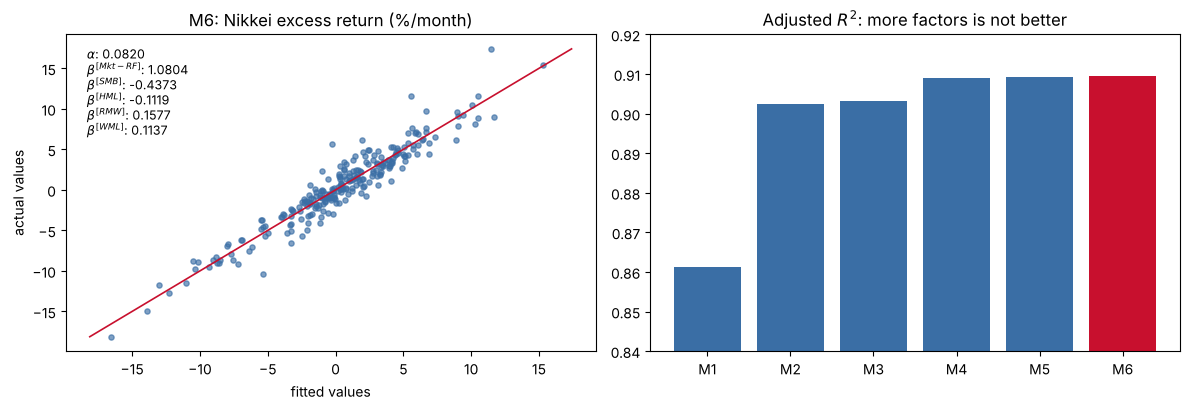

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))

ax[0].scatter(m6.fittedvalues, J["NKY_EX"], s=14, color=NAVY, alpha=.65)
lim = [J["NKY_EX"].min(), J["NKY_EX"].max()]
ax[0].plot(lim, lim, color=RED, lw=1.2)
ax[0].set_xlabel("fitted values"); ax[0].set_ylabel("actual values")
ax[0].set_title("M6: Nikkei excess return (%/month)")
ax[0].text(0.04, 0.96, "\n".join([r"$\alpha$: %.4f" % m6.params["const"]] +
           [r"$\beta^{[%s]}$: %.4f" % (f, m6.params[f]) for f in SPECS["M6 FINAL FF5-CMA+WML"]]),
           transform=ax[0].transAxes, va="top", fontsize=9)

ax[1].bar(range(len(SPECS)), [FITS[k].rsquared_adj for k in SPECS], color=NAVY)
ax[1].bar(list(SPECS).index("M6 FINAL FF5-CMA+WML"), m6.rsquared_adj, color=RED)
ax[1].set_xticks(range(len(SPECS)))
ax[1].set_xticklabels([k.split()[0] for k in SPECS])
ax[1].set_ylim(0.84, 0.92); ax[1].set_title("Adjusted $R^2$: more factors is not better")
plt.tight_layout(); plt.show()

## 10. Session 7 applied: what excess return should an investor expect?

Equation (8.1) of Session 7 states that for **traded factor portfolios** the price of risk is the factor's own
average return, so

$$E[R_{NKY}-R_f]=\sum_j \beta_j \lambda_j, \qquad \lambda_j = \overline{F_j}$$

Each factor is itself a strategy an investor can buy. Holding the Nikkei is therefore equivalent to holding
that beta-weighted portfolio of strategies, and the expected excess return follows. Alpha is not significant,
so it is set to zero rather than counted as free money.

In [17]:
fac = SPECS["M6 FINAL FF5-CMA+WML"]
prem = J[fac].mean()
contrib = m6.params[fac] * prem

bp = pd.DataFrame({"Beta": m6.params[fac], "p-value": m6.pvalues[fac],
                   "Premium lambda (%/m)": prem, "Contribution (%/m)": contrib})
print(bp.to_string(float_format=lambda x: f"{x:14.6f}"))
print(f"\nAlpha = {m6.params['const']:.4f} (p = {m6.pvalues['const']:.3f}), not significant -> set to 0")
print(f"\nExpected excess return   {contrib.sum():.4f} %/month   =   {contrib.sum()*12:.3f} %/year")
print(f"Realised average         {J['NKY_EX'].mean():.4f} %/month   =   {J['NKY_EX'].mean()*12:.3f} %/year")
print("\nThe gap between the two is the alpha the data refuse to call significant.")
print("Message to the client: the Nikkei is essentially a leveraged bet on the Japanese market")
print("(beta 1.08), tilted to large caps and growth, with a modest momentum exposure.")

                 Beta        p-value  Premium lambda (%/m)  Contribution (%/m)
Mkt-RF       1.080416       0.000000              0.382460            0.413216
SMB         -0.437324       0.000000              0.016331           -0.007142
HML         -0.111937       0.015198              0.398024           -0.044554
RMW          0.157654       0.036921             -0.075645           -0.011926
WML          0.113681       0.000032              0.013185            0.001499

Alpha = 0.0820 (p = 0.397), not significant -> set to 0

Expected excess return   0.3511 %/month   =   4.213 %/year
Realised average         0.4331 %/month   =   5.197 %/year

The gap between the two is the alpha the data refuse to call significant.
Message to the client: the Nikkei is essentially a leveraged bet on the Japanese market
(beta 1.08), tilted to large caps and growth, with a modest momentum exposure.


## 11. Session 8: maximum likelihood

Until now OLS estimated a conditional mean. Maximum likelihood asks a different question: which parameter
values make the sample we observed the most plausible? For
$y_t \mid F_t \sim N(x_t'\beta,\sigma^2)$ the log-likelihood is

$$\ell(\beta,\sigma^2)=-\frac{T}{2}\log(2\pi\sigma^2)-\frac{1}{2\sigma^2}\sum_t (y_t-x_t'\beta)^2$$

Maximising it in $\beta$ means minimising the sum of squared residuals, so **under normality the MLE of
$\beta$ is exactly the OLS estimator**. We verify this numerically rather than assert it.

In [18]:
from scipy import optimize

y  = J["NKY_EX"].values
Xm = sm.add_constant(J[fac]).values
T, k = Xm.shape

def neg_loglik(theta):
    b, log_s = theta[:k], theta[k]
    s2 = np.exp(2 * log_s)
    e  = y - Xm @ b
    return 0.5 * T * np.log(2 * np.pi * s2) + 0.5 * (e @ e) / s2

res  = optimize.minimize(neg_loglik, np.r_[np.zeros(k), np.log(y.std())], method="BFGS")
b_ml = res.x[:k]

print(f"{'parameter':<12}{'MLE (BFGS)':>14}{'OLS':>14}{'difference':>14}")
for i, nm in enumerate(["const"] + fac):
    print(f"{nm:<12}{b_ml[i]:14.8f}{m6.params.iloc[i]:14.8f}{b_ml[i]-m6.params.iloc[i]:14.2e}")
print(f"\nMaximum log-likelihood  l = {m6.llf:.4f}   (statsmodels: {res.fun*-1:.4f})")

s2_ml, s2_ols = m6.ssr / T, m6.ssr / (T - k)
print(f"\nsigma2_ML = SSR/T     = {s2_ml:.6f}   biased downwards, it ignores the k estimated means")
print(f"s2_OLS    = SSR/(T-k) = {s2_ols:.6f}   unbiased, this is what the standard errors use")
print(f"ratio (T-k)/T = {(T-k)/T:.4f}: the MLE is biased in finite samples but consistent as T grows.")

parameter       MLE (BFGS)           OLS    difference
const           0.08200318    0.08200317      5.11e-09
Mkt-RF          1.08041599    1.08041600     -8.57e-09
SMB            -0.43732386   -0.43732385     -6.03e-09
HML            -0.11193717   -0.11193715     -1.28e-08
RMW             0.15765362    0.15765362     -3.91e-09
WML             0.11368105    0.11368106     -1.01e-08

Maximum log-likelihood  l = -447.9318   (statsmodels: -447.9318)

sigma2_ML = SSR/T     = 2.169456   biased downwards, it ignores the k estimated means
s2_OLS    = SSR/(T-k) = 2.223244   unbiased, this is what the standard errors use
ratio (T-k)/T = 0.9758: the MLE is biased in finite samples but consistent as T grows.


### Likelihood-ratio tests, next to the F-tests

$$LR = 2(\ell_{unrestricted}-\ell_{restricted}) \;\xrightarrow{d}\; \chi^2(q)$$

The F-test is exact under normality, the LR test is asymptotic. If they disagree, the sample is too small or
normality is doing too much work. Here they agree on every decision, which is reassuring.

In [19]:
from scipy import stats as st
print(f"{'restriction':<26}{'q':>3}{'LR':>10}{'p (LR)':>11}{'F':>10}{'p (F)':>11}")
for lab, u, r in [("WML adds to FF5",        FITS["M5 FF5 + WML"],      FITS["M3 FF5"]),
                  ("CMA can be dropped",     FITS["M5 FF5 + WML"],      FITS["M6 FINAL FF5-CMA+WML"]),
                  ("Yen and S&P add to FF5", FITS["M4 FF5 + external"], FITS["M3 FF5"])]:
    q  = int(u.df_model - r.df_model)
    LR = 2 * (u.llf - r.llf)
    Fv, p_f, _ = u.compare_f_test(r)
    print(f"{lab:<26}{q:3d}{LR:10.4f}{st.chi2.sf(LR,q):11.6f}{float(Fv):10.4f}{float(p_f):11.6f}")

restriction                 q        LR     p (LR)         F      p (F)
WML adds to FF5             1   16.6525   0.000045   16.7381   0.000059
CMA can be dropped          1    0.1221   0.726748    0.1187   0.730748
Yen and S&P add to FF5      2   17.2237   0.000182    8.6303   0.000240


### AIC and BIC: the factor zoo under control

The likelihood also gives information criteria, $AIC=-2\ell+2k$ and $BIC=-2\ell+k\log T$. Both penalise
parameters; BIC penalises harder. They are the model-selection answer to the 316-factor problem.

In [20]:
sel = comp[["k", "R2", "Adj R2", "logL", "AIC", "BIC"]].copy()
sel["dAIC"] = sel["AIC"] - sel["AIC"].min()
sel["dBIC"] = sel["BIC"] - sel["BIC"].min()
print(sel.to_string(float_format=lambda x: f"{x:11.3f}"))
print(f"\nLowest AIC: {sel['AIC'].idxmin()}")
print(f"Lowest BIC: {sel['BIC'].idxmin()}")
print("\nThe nested F-tests, the adjusted R2, AIC and BIC all select the same model, M6.")
print("Note that M4 (yen + S&P on top of FF5) wins on raw R2 but loses on BIC: the two external")
print("drivers are statistically real yet too weak to justify two extra parameters here.")

                               k          R2      Adj R2        logL         AIC         BIC        dAIC        dBIC
M1 CAPM                    1.000       0.862       0.861    -503.070    1010.141    1017.168     102.277      88.223
M2 FF3                     3.000       0.904       0.902    -458.459     924.919     938.972      17.055      10.028
M3 FF5                     5.000       0.905       0.903    -456.197     924.394     945.475      16.530      16.530
M4 FF5 + external          7.000       0.912       0.909    -447.585     911.170     939.278       3.307      10.334
M5 FF5 + WML               6.000       0.911       0.909    -447.871     909.742     934.336       1.878       5.391
M6 FINAL FF5-CMA+WML       5.000       0.911       0.910    -447.932     907.864     928.944       0.000       0.000

Lowest AIC: M6 FINAL FF5-CMA+WML
Lowest BIC: M6 FINAL FF5-CMA+WML

The nested F-tests, the adjusted R2, AIC and BIC all select the same model, M6.
Note that M4 (yen + S&P on top of

## 12. Session 8 applied: are Nikkei returns normal, and how rare was the shock?

Section 2 showed excess kurtosis and a rejected Jarque-Bera. Maximum likelihood lets us put a number on it:
fit a normal and a Student-$t$ to the same returns and compare their likelihoods. The Student-$t$ nests the
normal as $\nu\to\infty$, so the comparison is a likelihood-ratio test on one parameter.

In [21]:
r = data[Y].dropna().values * 100            # Nikkei monthly log return, %

mu_n, sd_n = st.norm.fit(r)
ll_n = st.norm.logpdf(r, mu_n, sd_n).sum()
df_t, loc_t, sc_t = st.t.fit(r)
ll_t = st.t.logpdf(r, df_t, loc_t, sc_t).sum()
LR_t = 2 * (ll_t - ll_n)

print(f"Normal     mu = {mu_n:7.4f}  sigma = {sd_n:6.4f}              logL = {ll_n:10.4f}  AIC = {-2*ll_n+4:9.3f}")
print(f"Student-t  mu = {loc_t:7.4f}  scale = {sc_t:6.4f}  df = {df_t:5.2f}  logL = {ll_t:10.4f}  AIC = {-2*ll_t+6:9.3f}")
print(f"\nLR = {LR_t:.4f} on 1 restriction, p = {st.chi2.sf(LR_t,1):.3g}: normality is rejected.")
print(f"About {df_t:.1f} degrees of freedom means genuinely fat tails.\n")

print(f"{'month':<28}{'return':>9}{'P(worse) normal':>18}{'1 in':>12}{'P(worse) t':>14}{'1 in':>10}")
for lab, x in [(f"worst in sample ({data[Y].idxmin():%b %Y})", r.min()),
               ("March 2026 oil shock", data.loc[BREAK, Y] * 100)]:
    pn, pt = st.norm.cdf(x, mu_n, sd_n), st.t.cdf(x, df_t, loc_t, sc_t)
    print(f"{lab:<28}{x:8.2f}%{pn:18.2e}{1/pn:12,.0f}{pt:14.2e}{1/pt:10,.0f}")

print("\nUnder a normal law the 2008 crash was a once-in-3-million month, which is absurd in a sample")
print("of 250. The Student-t prices those tails sensibly. March 2026 is a tail event, not an impossible")
print("one, and that is the honest reading of the oil regime: a rare draw, not a new law of nature.")

Normal     mu =  0.6006  sigma = 5.5872              logL =  -784.8549  AIC =  1573.710
Student-t  mu =  0.8946  scale = 4.5732  df =  5.94  logL =  -778.4642  AIC =  1562.928

LR = 12.7815 on 1 restriction, p = 0.00035: normality is rejected.
About 5.9 degrees of freedom means genuinely fat tails.

month                          return   P(worse) normal        1 in    P(worse) t      1 in
worst in sample (Oct 2008)    -27.22%          3.20e-07   3,123,709      4.42e-04     2,262
March 2026 oil shock          -14.19%          4.05e-03         247      8.34e-03       120

Under a normal law the 2008 crash was a once-in-3-million month, which is absurd in a sample
of 250. The Student-t prices those tails sensibly. March 2026 is a tail event, not an impossible
one, and that is the honest reading of the oil regime: a rare draw, not a new law of nature.


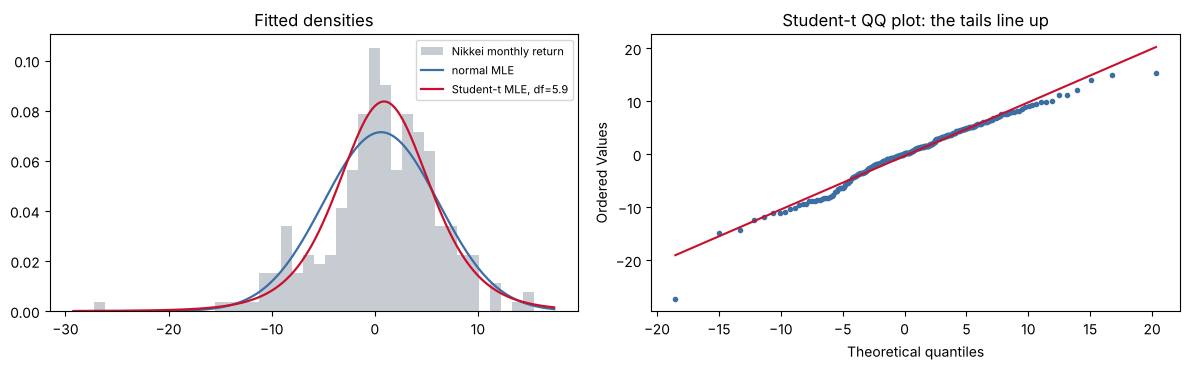

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
grid = np.linspace(r.min() - 2, r.max() + 2, 400)

ax[0].hist(r, bins=40, density=True, color=GREY, alpha=.75, label="Nikkei monthly return")
ax[0].plot(grid, st.norm.pdf(grid, mu_n, sd_n), color=NAVY, lw=1.6, label="normal MLE")
ax[0].plot(grid, st.t.pdf(grid, df_t, loc_t, sc_t), color=RED, lw=1.6,
           label=f"Student-t MLE, df={df_t:.1f}")
ax[0].legend(fontsize=8); ax[0].set_title("Fitted densities")

st.probplot(r, dist=st.t, sparams=(df_t, loc_t, sc_t), plot=ax[1])
ax[1].get_lines()[0].set(color=NAVY, ms=3); ax[1].get_lines()[1].set(color=RED)
ax[1].set_title("Student-t QQ plot: the tails line up")
plt.tight_layout(); plt.show()

### How much data does a maximum-likelihood estimate need?

The Session 8 script `MLGenerateEstimate.py` makes the point by simulation: draw samples of growing size
from a known law, re-estimate by ML, and watch the estimates tighten. We run it on the Student-$t$ fitted
above, which tells us how much to trust a parameter estimated on 7 months.

     N     mu hat   scale hat    df hat   se(mu hat)


    60     0.8890      4.5787      7.11       0.6521


   120     0.8963      4.6467      6.63       0.4433


   250     0.9229      4.5789      6.00       0.3499


   500     0.8968      4.5960      6.01       0.2322


  1000     0.8999      4.5882      5.94       0.1602


  5000     0.8912      4.5655      5.90       0.0747


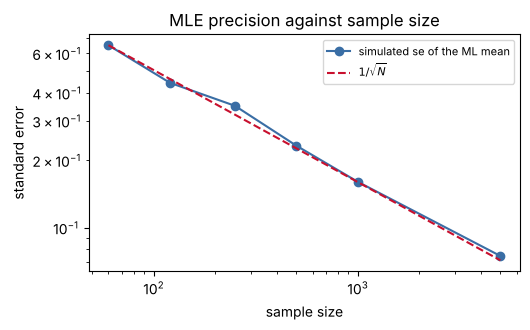


Our sample has 250 months. The 2026 oil regime has 7. The simulation is the quantitative
reason the regime result is presented as indicative: at that sample size the sampling error on a
mean is of the same order as the effect we are trying to measure.


In [23]:
rng = np.random.default_rng(20260314)
print(f"{'N':>6}{'mu hat':>11}{'scale hat':>12}{'df hat':>10}{'se(mu hat)':>13}")
sizes, se = [60, 120, 250, 500, 1000, 5000], []
for n in sizes:
    est = np.array([st.t.fit(st.t.rvs(df_t, loc_t, sc_t, size=n, random_state=rng))
                    for _ in range(200)])
    se.append(est[:, 1].std())
    print(f"{n:6d}{est[:,1].mean():11.4f}{est[:,2].mean():12.4f}{np.median(est[:,0]):10.2f}{se[-1]:13.4f}")

plt.figure(figsize=(5.4, 3.4))
plt.loglog(sizes, se, "o-", color=NAVY, label="simulated se of the ML mean")
plt.loglog(sizes, se[0]*np.sqrt(sizes[0]/np.array(sizes)), "--", color=RED, label=r"$1/\sqrt{N}$")
plt.xlabel("sample size"); plt.ylabel("standard error"); plt.legend(fontsize=8)
plt.title("MLE precision against sample size"); plt.tight_layout(); plt.show()

print(f"\nOur sample has {len(r)} months. The 2026 oil regime has 7. The simulation is the quantitative")
print("reason the regime result is presented as indicative: at that sample size the sampling error on a")
print("mean is of the same order as the effect we are trying to measure.")

## 13. Session 6: the six-step diagnosis of our own study

Session 6 gives the order in which any empirical result should be interrogated. We apply it to ourselves.

**1. Question.** Which macro-financial factors drive the monthly return of the Nikkei 225, do they survive
once Japan's own pricing factors are controlled for, and did the 2026 oil shock change the answer?

**2. Specification.** Model 1 regresses the Nikkei monthly log return on the yen, the S&P 500, Brent and the
change in the US-Japan 10-year gap, all month-end, 250 observations from December 2005 to September 2026.
Model 2 regresses the Nikkei excess return in USD on the Japan factors, 248 observations to August 2026.
The error term carries everything else: Japanese policy, domestic flows, measurement error.

**3. Estimation.** Each coefficient is a **partial** slope, the effect of that regressor holding the others
fixed. The yen loading of 0.87 and the S&P loading of 0.86 are the two that matter; the oil and rate-gap
loadings are indistinguishable from zero before 2026. In Model 2 the market beta of 1.08 means the Nikkei is
slightly more volatile than the Japanese market, and the negative SMB and HML loadings say it is a large-cap
growth index, which is what it is by construction.

**4. Inference.** t-tests on each loading; F-tests on groups (oil and the rate gap jointly, the style factors
jointly, momentum, CMA); t-tests of economically meaningful nulls such as $\beta_{S\&P}=1$; a predictive Chow
test for the 2026 break; likelihood-ratio tests as a cross-check. The 90% confidence level is the one the
client specified.

**5. Diagnostics.** Model 1 passes Breusch-Pagan, Breusch-Godfrey, Durbin-Watson, Jarque-Bera and VIF.
Model 2 with 2026 included fails homoskedasticity and normality, so it is read on Newey-West standard errors.
Returns are not normal (Student-$t$ with about 6 degrees of freedom), which inflates nothing in the point
estimates but matters for any tail statement.

**6. Decision.** Supported: the Nikkei is driven by the yen and by Wall Street; oil did not matter before
2026 and does since March 2026; the Nikkei's expected excess return is a beta-weighted sum of five tradable
factor premia, roughly 4.2% a year, with no significant alpha. **Not** supported: any causal claim, any
forecast built on the 7-month regime, and any suggestion that CMA or an unconditional oil effect belongs in
the model.

### Limitations, stated before anyone has to ask

1. **Seven months.** The oil-regime result rests on 7 observations. Section 12 quantifies how fragile an
   estimate on that sample size is.
2. **Correlation, not causation.** Nothing here identifies a causal channel. March 2026 bundles an oil shock
   with everything else that happened that month.
3. **September 2026 is also a rates shock.** The US 10-year moved from roughly 4.75% to 5.29%, so that month
   does not isolate oil.
4. **The break date is a choice.** March 2026 was selected because it is the largest Brent move and the month
   the Nikkei fell 14%, but a different cut-off would give somewhat different numbers.
5. **Two sample ends.** Model 1 runs to September 2026, Model 2 to August 2026, where French's Japan factors
   stop. The two are not month-for-month comparable.
6. **Factor premia are sample averages.** The 4.2% a year in section 10 is what these factors paid over
   2006 to 2026, not a promise about the future.
7. **One index, not a cross-section.** We explain the Nikkei's time series; we do not test whether these
   factors price Japanese stocks in the cross-section, which is the stronger asset-pricing claim.